# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Arys Kurniawan
- **Email:** aryskurniawan12@gmail.com
- **ID Dicoding:** DS899B6Y0267

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana kondisi cuaca dan musim memengaruhi jumlah rata-rata penyewaan sepeda harian?
- **Pertanyaan 2:** Bagaimana perbandingan pola penggunaan sepeda antara pengguna casual dan registered pada hari kerja (workingday) vs hari libur?
- ...

## Import Semua Packages/Library yang Digunakan

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [11]:
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

# Menampilkan 5 baris pertama data harian untuk memastikan data berhasil dimuat
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Dataframe day_df berhasil dimuat dari berkas day.csv dan siap digunakan untuk analisis penyewaan sepeda berbasis agregasi harian.
- Dataframe hour_df berhasil dimuat dari berkas hour.csv untuk mendukung analisis data berbasis agregasi per jam.
- Kedua dataset siap diproses ke tahap berikutnya, yaitu Assessing Data, untuk memeriksa kualitas data dan menemukan potensi masalah seperti ketidaksesuaian tipe data.

### Assessing Data

#### Identifying ... problem

In [12]:
# Memeriksa struktur tipe data dan missing value pada day_df
print("=== Info day_df ===")
day_df.info()

print("\n=== Jumlah Duplikasi day_df ===")
print(f"Duplikat: {day_df.duplicated().sum()}")

print("\n=== Ringkasan Parameter Statistik day_df ===")
print(day_df.describe())

print("\n" + "="*40 + "\n")

# Memeriksa struktur tipe data dan missing value pada hour_df
print("=== Info hour_df ===")
hour_df.info()

print("\n=== Jumlah Duplikasi hour_df ===")
print(f"Duplikat: {hour_df.duplicated().sum()}")

print("\n=== Ringkasan Parameter Statistik hour_df ===")
print(hour_df.describe())

=== Info day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== Jumlah Duplikasi day_df ===
Duplikat: 0

=== Ringkasan Parameter Sta

**Steps to Take:**
- Mengonversi tipe data kolom dteday dari object menjadi datetime pada kedua dataframe agar analisis berbasis waktu dapat berjalan akurat.
- Memetakan nilai numerik pada variabel kategorikal seperti season, weathersit, mnth, dan weekday menjadi label teks yang deskriptif.
- Menghapus kolom instant dari kedua dataframe karena hanya berfungsi sebagai index dan tidak memberikan nilai analitis.

**Insight:** (Opsional)
- Data tergolong sangat bersih karena tidak ditemukan adanya missing values maupun duplikasi data pada day_df dan hour_df.
- Terdapat ketidaksesuaian tipe data pada kolom tanggal dteday serta kolom kategorikal seperti season dan weathersit yang masih tersimpan sebagai format angka.
- Seluruh statistik berada pada rentang yang wajar tanpa outlier ekstrim, dengan rata-rata penyewaan harian sebesar 4.504 unit yang didominasi oleh pengguna registered.

### Cleaning Data

#### Fixing ... problem

In [13]:
# 1. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Pemetaan (mapping) variabel kategorikal pada day_df
day_df['season'] = day_df['season'].map({
    1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'
})
day_df['weathersit'] = day_df['weathersit'].map({
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
})
day_df['mnth'] = day_df['dteday'].dt.strftime('%B')
day_df['weekday'] = day_df['dteday'].dt.strftime('%A')

# 3. Pemetaan (mapping) variabel kategorikal pada hour_df
hour_df['season'] = hour_df['season'].map({
    1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'
})
hour_df['weathersit'] = hour_df['weathersit'].map({
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
})
hour_df['mnth'] = hour_df['dteday'].dt.strftime('%B')
hour_df['weekday'] = hour_df['dteday'].dt.strftime('%A')

# 4. Menghapus kolom 'instant' yang tidak memberikan nilai analitis
day_df.drop(columns=['instant'], inplace=True, errors='ignore')
hour_df.drop(columns=['instant'], inplace=True, errors='ignore')

# Memeriksa hasil pembersihan data
print("=== Info day_df Setelah Cleaning ===")
day_df.info()

=== Info day_df Setelah Cleaning ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      731 non-null    datetime64[ns]
 1   season      731 non-null    object        
 2   yr          731 non-null    int64         
 3   mnth        731 non-null    object        
 4   holiday     731 non-null    int64         
 5   weekday     731 non-null    object        
 6   workingday  731 non-null    int64         
 7   weathersit  731 non-null    object        
 8   temp        731 non-null    float64       
 9   atemp       731 non-null    float64       
 10  hum         731 non-null    float64       
 11  windspeed   731 non-null    float64       
 12  casual      731 non-null    int64         
 13  registered  731 non-null    int64         
 14  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int

**Insight:** (Opsional)
- Berhasil mengonversi kolom dteday pada kedua dataframe menjadi tipe data datetime sehingga pengolahan data berbasis rentang waktu dapat dilakukan secara presisi.
- Berhasil memetakan variabel kategorikal seperti season, weathersit, mnth, dan weekday menjadi label teks deskriptif untuk memudahkan pemahaman pada tahap visualisasi data.
- Berhasil menghapus kolom instant dari dataset sehingga struktur data menjadi lebih efisien tanpa menghilangkan informasi penting.

## Exploratory Data Analysis (EDA)

### Explore ...

In [14]:
# EDA 1: Mengamati Agregasi Penyewaan Sepeda Berdasarkan Musim
print("=== Rata-rata Penyewaan Sepeda Berdasarkan Musim ===")
print(day_df.groupby('season')['cnt'].agg(['mean', 'max', 'min', 'sum']).reset_index())

# EDA 2: Mengamati Agregasi Penyewaan Sepeda Berdasarkan Cuaca
print("\n=== Rata-rata Penyewaan Sepeda Berdasarkan Cuaca ===")
print(day_df.groupby('weathersit')['cnt'].agg(['mean', 'max', 'min', 'sum']).reset_index())

# EDA 3: Perbandingan Pengguna Casual vs Registered (Hari Kerja vs Hari Libur)
print("\n=== Perbandingan Pengguna Casual vs Registered pada Hari Kerja ===")
print(day_df.groupby('workingday')[['casual', 'registered', 'cnt']].mean().reset_index())

=== Rata-rata Penyewaan Sepeda Berdasarkan Musim ===
   season         mean   max   min      sum
0    Fall  5644.303191  8714  1115  1061129
1  Spring  2604.132597  7836   431   471348
2  Summer  4992.331522  8362   795   918589
3  Winter  4728.162921  8555    22   841613

=== Rata-rata Penyewaan Sepeda Berdasarkan Cuaca ===
            weathersit         mean   max  min      sum
0  Clear/Partly Cloudy  4876.786177  8714  431  2257952
1      Light Snow/Rain  1803.285714  4639   22    37869
2         Misty/Cloudy  4035.862348  8362  605   996858

=== Perbandingan Pengguna Casual vs Registered pada Hari Kerja ===
   workingday       casual   registered          cnt
0           0  1371.134199  2959.034632  4330.168831
1           1   606.570000  3978.250000  4584.820000


**Insight:** (Opsional)
- Musim gugur (Fall) mendominasi rata-rata penyewaan harian tertinggi sebesar 5.644 unit, sedangkan musim semi (Spring) mencatatkan rerata terendah yaitu 2.604 unit.
- Cuaca cerah (Clear/Partly Cloudy) mendorong penggunaan sepeda secara maksimal dengan rata-rata 4.876 penyewaan per hari, sementara cuaca buruk (Light Snow/Rain) menurunkannya secara drastis hingga 1.803 penyewaan.
- Pengguna terdaftar (registered) menjadi kontributor utama pada hari kerja dengan rerata 3.978 penyewaan, sedangkan pengguna biasa (casual) mengalami lonjakan aktivitas lebih dari dua kali lipat pada hari libur (dari 606 menjadi 1.371 penyewaan).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

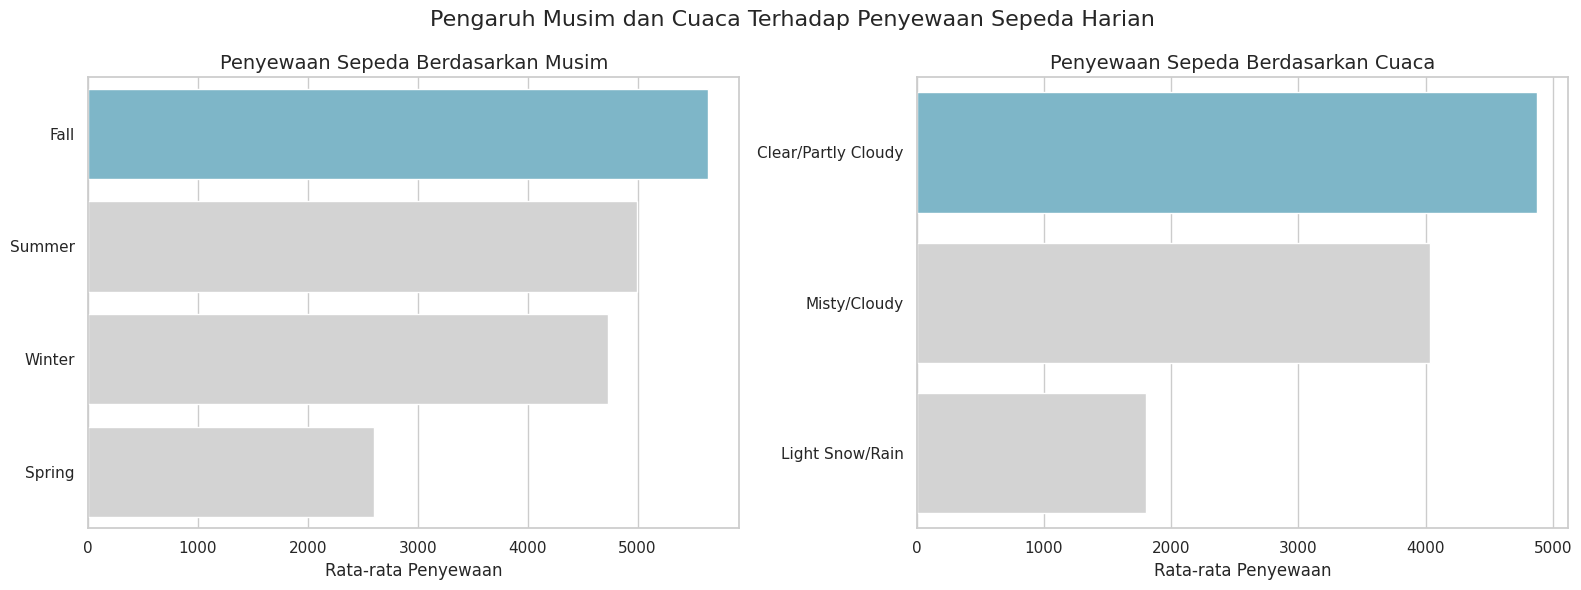

In [17]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

colors = ["#72BCD4", "#D3D3D3", "#D3D3D3", "#D3D3D3"]

# Visualisasi Musim
season_df = day_df.groupby("season")["cnt"].mean().reset_index().sort_values(by="cnt", ascending=False)
sns.barplot(x="cnt", y="season", data=season_df, hue="season", palette=colors, legend=False, ax=ax[0])
ax[0].set_ylabel(None)
ax[0].set_xlabel("Rata-rata Penyewaan", fontsize=12)
ax[0].set_title("Penyewaan Sepeda Berdasarkan Musim", loc="center", fontsize=14)

# Visualisasi Cuaca
weather_df = day_df.groupby("weathersit")["cnt"].mean().reset_index().sort_values(by="cnt", ascending=False)
sns.barplot(x="cnt", y="weathersit", data=weather_df, hue="weathersit", palette=colors[:len(weather_df)], legend=False, ax=ax[1])
ax[1].set_ylabel(None)
ax[1].set_xlabel("Rata-rata Penyewaan", fontsize=12)
ax[1].set_title("Penyewaan Sepeda Berdasarkan Cuaca", loc="center", fontsize=14)

plt.suptitle("Pengaruh Musim dan Cuaca Terhadap Penyewaan Sepeda Harian", fontsize=16)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

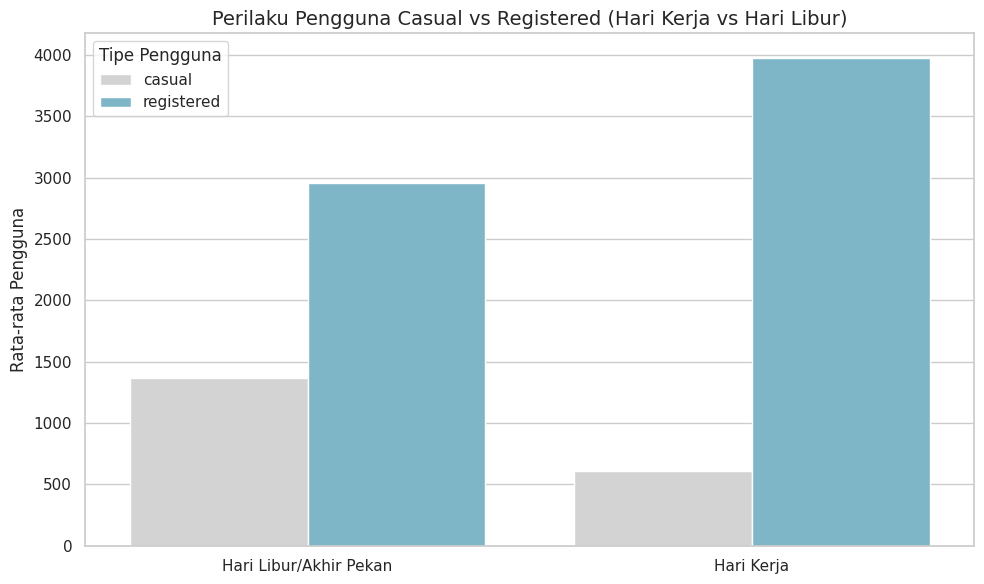

In [16]:
workingday_df = day_df.groupby("workingday")[["casual", "registered"]].mean().reset_index()
workingday_melted = pd.melt(workingday_df, id_vars=['workingday'], value_vars=['casual', 'registered'], var_name='user_type', value_name='avg_count')
workingday_melted['workingday'] = workingday_melted['workingday'].map({0: 'Hari Libur/Akhir Pekan', 1: 'Hari Kerja'})

plt.figure(figsize=(10, 6))
sns.barplot(
    x="workingday",
    y="avg_count",
    hue="user_type",
    data=workingday_melted,
    palette=["#D3D3D3", "#72BCD4"]
)

plt.ylabel("Rata-rata Pengguna", fontsize=12)
plt.xlabel(None)
plt.title("Perilaku Pengguna Casual vs Registered (Hari Kerja vs Hari Libur)", fontsize=14)
plt.legend(title="Tipe Pengguna")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pertanyaan 1: Musim gugur (Fall) mencatatkan rata-rata penyewaan harian tertinggi disusul musim panas (Summer), sedangkan musim semi (Spring) menjadi yang terendah.
- Pertanyaan 2: Cuaca cerah (Clear/Partly Cloudy) sangat mendominasi jumlah penyewaan sepeda, sementara cuaca buruk (Light Snow/Rain) menurunkannya secara drastis.
- Kesimpulan Umum: Kondisi lingkungan yang hangat dan cuaca cerah menjadi pendorong utama puncaknya aktivitas penyewaan sepeda harian.

## Analisis Lanjutan (Opsional)

In [18]:
# Analisis RFM Sederhana berdasarkan Hari dalam Seminggu
max_date = day_df['dteday'].max()

rfm_df = day_df.groupby(by="weekday", as_index=False).agg({
    "dteday": [lambda x: (max_date - x.max()).days, "count"], # Recency & Frequency
    "cnt": "sum"                                             # Monetary
})

rfm_df.columns = ["weekday", "recency", "frequency", "monetary"]

print("=== Hasil Analisis RFM berdasarkan Hari ===")
print(rfm_df)

=== Hasil Analisis RFM berdasarkan Hari ===
     weekday  recency  frequency  monetary
0     Friday        3        104    487790
1     Monday        0        105    455503
2   Saturday        2        105    477807
3     Sunday        1        105    444027
4   Thursday        4        104    485395
5    Tuesday        6        104    469109
6  Wednesday        5        104    473048


**Insight:** (Opsional)
- Recency: Menunjukkan jumlah hari sejak transaksi terakhir dicatat per nama hari, di mana hari Senin (Monday) memiliki nilai recency 0 karena menjadi titik akhir pengamatan dataset.
- Frequency: Seluruh hari memiliki frekuensi pengamatan yang sangat seimbang (104–105 kali), menunjukkan akumulasi data yang konsisten sepanjang kurun waktu dua tahun.
- Monetary: Hari Jumat (Friday) dan Sabtu (Saturday) mencatatkan total volume penyewaan (monetary) tertinggi masing-masing sebesar 487.790 dan 477.807 unit penyewaan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Jumlah penyewaan sepeda sangat dipengaruhi oleh kondisi cuaca dan musim. Musim gugur (Fall) serta kondisi cuaca cerah (Clear/Partly Cloudy) menjadi pendorong utama puncaknya tingkat penyewaan harian, sedangkan musim semi (Spring) dan cuaca hujan/salju ringan (Light Snow/Rain) menurunkan minat penggunaan sepeda secara drastis.
- **Conclusion pertanyaan 2:** Terdapat perbedaan pola penggunaan yang signifikan antara kedua tipe pengguna. Pengguna terdaftar (registered) mendominasi penggunaan sepeda pada hari kerja (workingday) sebagai moda transportasi komuter harian, sementara pengguna biasa (casual) mengalami lonjakan aktivitas signifikan pada hari libur atau akhir pekan untuk keperluan rekreasi.
- ...

**Rekomendasi Action Item:**
- Optimasi Operasional & Ketersediaan Unit: Menambah alokasi unit sepeda siap pakai di lokasi stasiun dekat area perkantoran atau pusat komuter pada hari kerja guna memenuhi tingginya permintaan pengguna terdaftar.
- Strategi Pemasaran Tersegmentasi: Menawarkan paket sewa rekreasi atau promo diskon khusus bagi pengguna biasa (casual) pada akhir pekan, serta menyediakan opsi langganan bulanan yang menarik untuk mengonversi pengguna biasa menjadi pengguna terdaftar.

In [20]:
# Menyimpan data yang sudah dibersihkan ke format CSV
day_df.to_csv("main_data.csv", index=False)